In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path


In [3]:

file_path = Path(
    r"I:\Muzzamil Data Analyst\OBSIS Intership Project\OIBSIP DataAnalytics-L1-SentimentAnalysis\twitter_training.csv"
)

df = pd.read_csv(
    file_path,
    header=None,
    names=["Tweet_ID", "Entity", "Sentiment", "Tweet"]
)

print("Dataset shape:", df.shape)
df.head()


Dataset shape: (74682, 4)


,Tweet_ID,Entity,Sentiment,Tweet
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


In [5]:

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nSentiment counts:")
print(df["Sentiment"].value_counts())

print("\nDuplicate rows:", df.duplicated().sum())


Column names:
['Tweet_ID', 'Entity', 'Sentiment', 'Tweet']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74682 entries, 0 to 74681
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Tweet_ID   74682 non-null  int64 
 1   Entity     74682 non-null  object
 2   Sentiment  74682 non-null  object
 3   Tweet      73996 non-null  object
dtypes: int64(1), object(3)
memory usage: 2.3+ MB

Missing values:
Tweet_ID       0
Entity         0
Sentiment      0
Tweet        686
dtype: int64

Sentiment counts:
Sentiment
Negative      22542
Positive      20832
Neutral       18318
Irrelevant    12990
Name: count, dtype: int64

Duplicate rows: 2700


In [7]:

df_clean = df.copy()

# Standardize sentiment labels
df_clean["Sentiment"] = df_clean["Sentiment"].str.strip().str.title()

print(df_clean["Sentiment"].value_counts(dropna=False))


Sentiment
Negative      22542
Positive      20832
Neutral       18318
Irrelevant    12990
Name: count, dtype: int64


In [9]:

print("Rows before cleaning:", len(df_clean))

# Remove rows with missing or blank tweets
df_clean = df_clean.dropna(subset=["Tweet"])
df_clean = df_clean[
    df_clean["Tweet"].astype(str).str.strip().ne("")
]

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

print("Rows after removing missing tweets and duplicates:", len(df_clean))
print("Missing tweets remaining:", df_clean["Tweet"].isna().sum())
print("Duplicate rows remaining:", df_clean.duplicated().sum())


Rows before cleaning: 74682
Rows after removing missing tweets and duplicates: 71484
Missing tweets remaining: 0
Duplicate rows remaining: 0


In [11]:

required_sentiments = ["Positive", "Negative", "Neutral"]

df_clean = df_clean[
    df_clean["Sentiment"].isin(required_sentiments)
].copy()

print("Final cleaned dataset shape:", df_clean.shape)
print("\nFinal sentiment distribution:")
print(df_clean["Sentiment"].value_counts())

print("\nMissing values:")
print(df_clean.isnull().sum())


Final cleaned dataset shape: (58980, 4)

Final sentiment distribution:
Sentiment
Negative    21652
Positive    19677
Neutral     17651
Name: count, dtype: int64

Missing values:
Tweet_ID     0
Entity       0
Sentiment    0
Tweet        0
dtype: int64


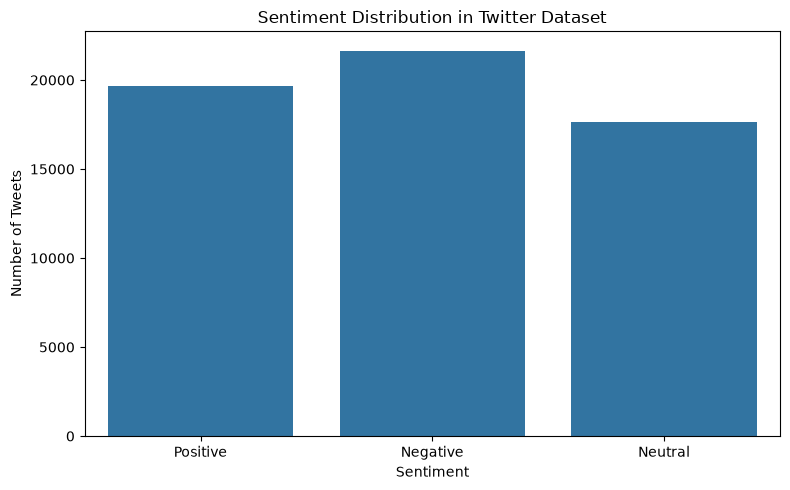

In [13]:

plt.figure(figsize=(8, 5))

sentiment_order = ["Positive", "Negative", "Neutral"]

sns.countplot(
    data=df_clean,
    x="Sentiment",
    order=sentiment_order
)

plt.title("Sentiment Distribution in Twitter Dataset")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.tight_layout()
plt.show()


In [14]:

sentiment_counts = df_clean["Sentiment"].value_counts()
sentiment_percentages = (
    df_clean["Sentiment"].value_counts(normalize=True) * 100
).round(2)

distribution = pd.DataFrame({
    "Count": sentiment_counts,
    "Percentage": sentiment_percentages
})

display(distribution)


,Count,Percentage
Sentiment,,
Negative,21652,36.71
Positive,19677,33.36
Neutral,17651,29.93


### Sentiment Distribution

The bar chart displays the distribution of positive, negative, and neutral tweets in the cleaned dataset. Comparing the number of tweets in each class helps us understand whether the dataset is balanced or whether some sentiment classes are more common than others. This information is useful when evaluating the performance of our classification models.

In [18]:

%pip install nltk


Note: you may need to restart the kernel to use updated packages.


In [21]:
import nltk
import re
import string

from nltk.corpus import stopwords
from nltk.tokenize import TweetTokenizer

nltk.download("stopwords")

tokenizer = TweetTokenizer()

stop_words = set(stopwords.words("english"))

# Keep important negation words
stop_words = stop_words - {"no", "not", "nor", "never"}


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


In [23]:
def preprocess_text(text):
    # Convert text to lowercase
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove mentions
    text = re.sub(r"@\w+", "", text)

    # Remove punctuation and numbers
    text = re.sub(r"[^a-z\s]", " ", text)

    # Tokenization
    tokens = tokenizer.tokenize(text)

    # Remove stopwords and single-character tokens
    tokens = [
        word for word in tokens
        if word not in stop_words and len(word) > 1
    ]

    return " ".join(tokens)


In [25]:
df_clean["Clean_Tweet"] = df_clean["Tweet"].apply(preprocess_text)

print("Preprocessing completed!")

display(
    df_clean[
        ["Tweet", "Clean_Tweet", "Sentiment"]
    ].head(10)
)


Preprocessing completed!


,Tweet,Clean_Tweet,Sentiment
0,im getting on borderlands and i will murder yo...,im getting borderlands murder,Positive
1,I am coming to the borders and I will kill you...,coming borders kill,Positive
2,im getting on borderlands and i will kill you ...,im getting borderlands kill,Positive
3,im coming on borderlands and i will murder you...,im coming borderlands murder,Positive
4,im getting on borderlands 2 and i will murder ...,im getting borderlands murder,Positive
5,im getting into borderlands and i can murder y...,im getting borderlands murder,Positive
6,So I spent a few hours making something for fu...,spent hours making something fun know huge fan...,Positive
7,So I spent a couple of hours doing something f...,spent couple hours something fun know huge bor...,Positive
8,So I spent a few hours doing something for fun...,spent hours something fun know huge borderland...,Positive
9,So I spent a few hours making something for fu...,spent hours making something fun know huge rha...,Positive


In [27]:

empty_count = (
    df_clean["Clean_Tweet"].str.strip() == ""
).sum()

print("Empty tweets after preprocessing:", empty_count)

df_clean = df_clean[
    df_clean["Clean_Tweet"].str.strip() != ""
].copy()

df_clean.reset_index(drop=True, inplace=True)

print("Final dataset shape:", df_clean.shape)


Empty tweets after preprocessing: 1290
Final dataset shape: (57690, 5)


### Text Preprocessing

Text preprocessing converts raw tweets into cleaner text suitable for machine learning. The process includes lowercasing, URL and punctuation removal, tokenization, and stopword removal. Important negation words are preserved to help the model recognize negative expressions.

### TF-IDF Feature Extraction

TF-IDF (Term Frequency–Inverse Document Frequency) converts text into numerical vectors for machine learning. It gives higher importance to words that are useful for distinguishing documents while reducing the importance of words that appear frequently across many documents.

We use `TfidfVectorizer` to transform the cleaned tweets into numerical features. The vectorizer is fitted only on the training data to prevent information leakage from the test data.

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

In [33]:

X = df_clean["Clean_Tweet"]
y = df_clean["Sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())


Training samples: 46152
Testing samples: 11538

Training sentiment distribution:
Sentiment
Negative    16988
Positive    15368
Neutral     13796
Name: count, dtype: int64

Testing sentiment distribution:
Sentiment
Negative    4247
Positive    3842
Neutral     3449
Name: count, dtype: int64


In [35]:

tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)


Training TF-IDF shape: (46152, 20000)
Testing TF-IDF shape: (11538, 20000)


In [37]:

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


In [39]:

# Model 1: Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

# Model 2: Logistic Regression
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)
lr_model.fit(X_train_tfidf, y_train)

print("Both models trained successfully!")


Both models trained successfully!


In [41]:

y_pred_nb = nb_model.predict(X_test_tfidf)
y_pred_lr = lr_model.predict(X_test_tfidf)

print("Naive Bayes predictions:", len(y_pred_nb))
print("Logistic Regression predictions:", len(y_pred_lr))


Naive Bayes predictions: 11538
Logistic Regression predictions: 11538


In [45]:

results = []

models_predictions = {
    "Naive Bayes": y_pred_nb,
    "Logistic Regression": y_pred_lr
}

for model_name, predictions in models_predictions.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (Macro)": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "F1-Score (Macro)": f1_score(
            y_test, predictions, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision (Macro)": "{:.4f}",
        "Recall (Macro)": "{:.4f}",
        "F1-Score (Macro)": "{:.4f}"
    })
)


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
0,Naive Bayes,0.7747,0.7806,0.7666,0.7680
1,Logistic Regression,0.8319,0.8321,0.8279,0.8292


In [47]:

print("NAIVE BAYES CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred_nb,
    labels=["Negative", "Neutral", "Positive"],
    zero_division=0
))

print("\nLOGISTIC REGRESSION CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred_lr,
    labels=["Negative", "Neutral", "Positive"],
    zero_division=0
))


NAIVE BAYES CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.76      0.86      0.81      4247
     Neutral       0.82      0.63      0.71      3449
    Positive       0.76      0.81      0.79      3842

    accuracy                           0.77     11538
   macro avg       0.78      0.77      0.77     11538
weighted avg       0.78      0.77      0.77     11538


LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.83      0.88      0.86      4247
     Neutral       0.84      0.76      0.80      3449
    Positive       0.82      0.84      0.83      3842

    accuracy                           0.83     11538
   macro avg       0.83      0.83      0.83     11538
weighted avg       0.83      0.83      0.83     11538



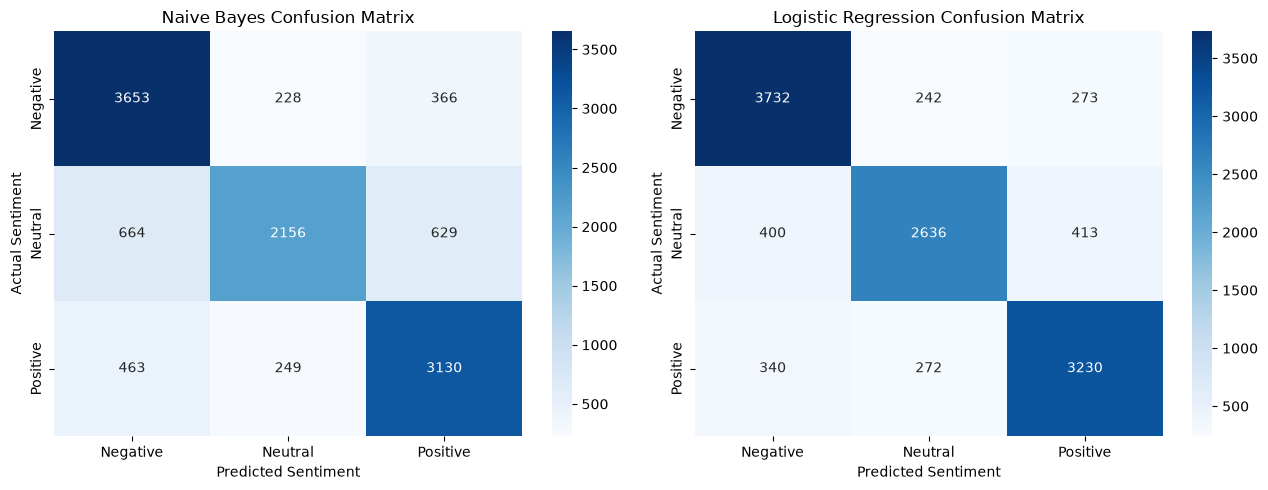

In [49]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

class_labels = ["Negative", "Neutral", "Positive"]

for ax, model_name, predictions in [
    (axes[0], "Naive Bayes", y_pred_nb),
    (axes[1], "Logistic Regression", y_pred_lr)
]:
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=class_labels
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels,
        ax=ax
    )

    ax.set_title(f"{model_name} Confusion Matrix")
    ax.set_xlabel("Predicted Sentiment")
    ax.set_ylabel("Actual Sentiment")

plt.tight_layout()
plt.show()


In [51]:
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.


In [53]:
from wordcloud import WordCloud

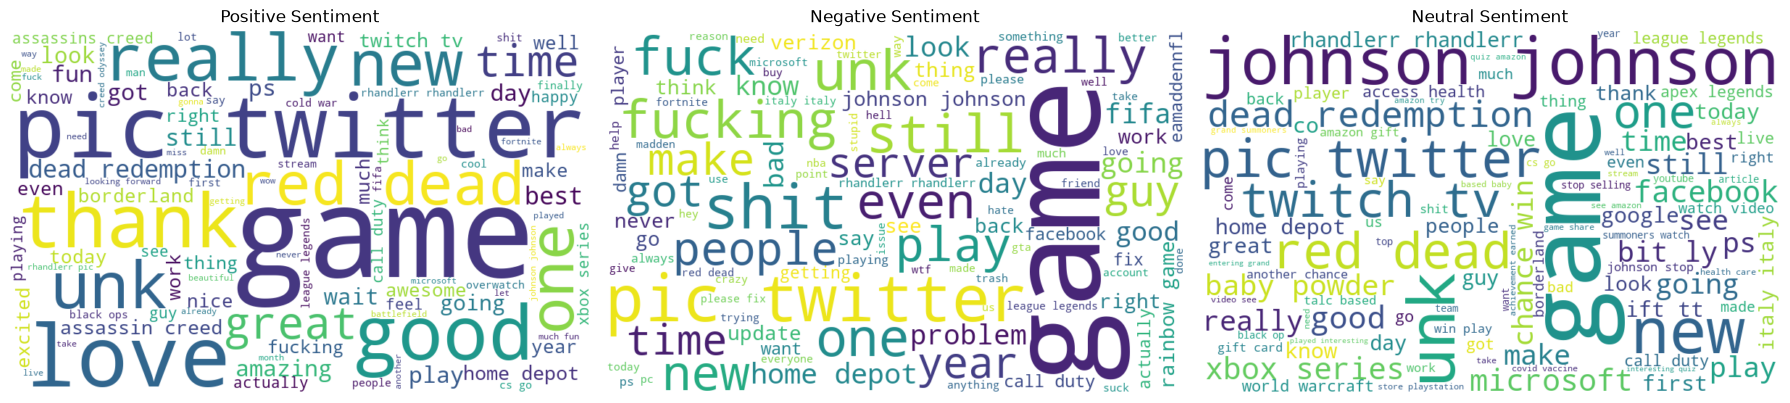

In [56]:
sentiments = ["Positive", "Negative", "Neutral"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, sentiment in zip(axes, sentiments):
    text = " ".join(
        df_clean.loc[
            df_clean["Sentiment"] == sentiment,
            "Clean_Tweet"
        ]
    )

    wordcloud = WordCloud(
        width=800,
        height=500,
        background_color="white",
        max_words=100
    ).generate(text)

    ax.imshow(wordcloud, interpolation="bilinear")
    ax.set_title(f"{sentiment} Sentiment")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [60]:
error_df = pd.DataFrame({
    "Original_Tweet": X_test.reset_index(drop=True),
    "Actual_Sentiment": y_test.reset_index(drop=True),
    "Naive_Bayes_Prediction": y_pred_nb,
    "Logistic_Regression_Prediction": y_pred_lr
})

# Select tweets misclassified by at least one model
errors = error_df[
    (error_df["Actual_Sentiment"] != error_df["Naive_Bayes_Prediction"]) |
    (error_df["Actual_Sentiment"] != error_df["Logistic_Regression_Prediction"])
]

display(errors.head(5))

,Original_Tweet,Actual_Sentiment,Naive_Bayes_Prediction,Logistic_Regression_Prediction
11,honestly,Negative,Positive,Positive
12,kid made scream,Positive,Positive,Negative
16,torn,Neutral,Positive,Positive
17,chicago know number nba myteam need card maybe...,Neutral,Negative,Negative
23,not first time eu commission taken step,Negative,Neutral,Neutral


Error Analysis

Some tweets may be misclassified because of sarcasm, slang, spelling mistakes, emojis, ambiguous wording, or words whose meanings depend on context. Short tweets may also lack enough information for reliable sentiment prediction. Reviewing misclassified examples helps identify areas where text preprocessing and model selection could be improved.

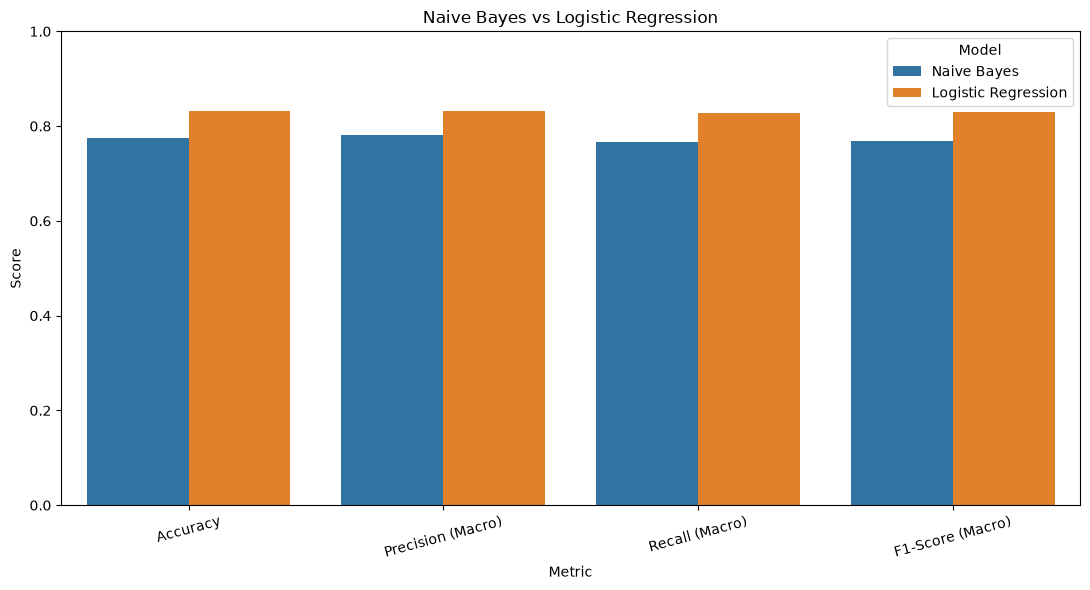

In [64]:
results_long = results_df.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Precision (Macro)",
        "Recall (Macro)",
        "F1-Score (Macro)"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=results_long,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Naive Bayes vs Logistic Regression")
plt.ylim(0, 1)
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## Conclusion

In this project, we developed a three-class sentiment analysis system to classify Twitter text as positive, negative, or neutral using Natural Language Processing (NLP) and machine learning.

The dataset was cleaned by handling missing tweet text, removing duplicate rows, and excluding the irrelevant sentiment category. Text preprocessing included lowercasing, URL and punctuation removal, tokenization, and stopword removal. TF-IDF Vectorization was used to convert text into numerical features, and the dataset was split into 80% training data and 20% testing data.

Two machine learning algorithms were trained and evaluated: Multinomial Naive Bayes and Logistic Regression.

Logistic Regression performed better, achieving **83.19% accuracy, 83.21% macro precision, 82.79% macro recall, and 82.92% macro F1-score**. Naive Bayes achieved 77.47% accuracy and a 76.80% macro F1-score.

Based on these results, Logistic Regression was the better-performing model on the test dataset. This model could be useful for analyzing customer feedback, monitoring public opinion on social media, and identifying general sentiment trends.

However, the model may misclassify tweets containing sarcasm, slang, ambiguous expressions, or context-dependent language. Further improvements could include testing additional algorithms, tuning hyperparameters, and using more advanced language models.